# Guardrails example

A minimal chatbot that only answers cooking questions.

- **Input guardrail**: classifies the user's question as `on_topic` or `off_topic` before it reaches the LLM.
- **Output guardrail**: scans the LLM's reply for banned words before it reaches the user.

Both guardrails are just graph nodes with a conditional edge, the same shape as the conditional workflow in notebook 3.

In [10]:
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage, HumanMessage
from dotenv import load_dotenv
import os

load_dotenv()
model = ChatOpenAI(model=os.getenv('OPENAI_MODEL', 'gpt-4o-mini'))

In [11]:
class GuardrailState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    verdict: str          # 'on_topic' or 'off_topic', set by the input guardrail
    final_answer: str     # what we actually show the user

In [12]:
# --- Input guardrail: is this question about cooking? ---

class TopicCheck(BaseModel):
    topic: Literal['on_topic', 'off_topic'] = Field(
        description="'on_topic' if the question is about cooking, food or recipes, else 'off_topic'"
    )

topic_classifier = model.with_structured_output(TopicCheck)

def input_guardrail(state: GuardrailState):
    question = state['messages'][-1].content
    result = topic_classifier.invoke(
        f"Classify this question. Only cooking, food and recipe questions are on_topic.\n\nQuestion: {question}"
    )
    return {'verdict': result.topic}

def route_after_input_guardrail(state: GuardrailState) -> Literal['chat_node', 'rejection_node']:
    return 'chat_node' if state['verdict'] == 'on_topic' else 'rejection_node'

In [13]:
# --- Normal chat node: only reached if the input guardrail allowed it ---

def chat_node(state: GuardrailState):
    response = model.invoke(state['messages'])
    return {'messages': [response]}

def rejection_node(state: GuardrailState):
    message = "I can only help with cooking and recipe questions. Please ask me something about food."
    return {'final_answer': message}

In [14]:
# --- Output guardrail: block replies that leak banned words ---
# A real system would check for things like PII, profanity, unsafe advice.
# This is a simple keyword check to keep the example readable.

import re

BANNED_WORDS = ['kill', 'poison', 'weapon']
# Word-boundary regex, so 'kill' does not match inside 'skillet'.
BANNED_PATTERN = re.compile(r'\b(' + '|'.join(BANNED_WORDS) + r')\b', re.IGNORECASE)

def output_guardrail(state: GuardrailState):
    reply = state['messages'][-1].content
    if BANNED_PATTERN.search(reply):
        return {'final_answer': "I can't share that response. Please rephrase your question."}
    return {'final_answer': reply}

In [15]:
graph = StateGraph(GuardrailState)

graph.add_node('input_guardrail', input_guardrail)
graph.add_node('chat_node', chat_node)
graph.add_node('rejection_node', rejection_node)
graph.add_node('output_guardrail', output_guardrail)

graph.add_edge(START, 'input_guardrail')
graph.add_conditional_edges('input_guardrail', route_after_input_guardrail)

graph.add_edge('chat_node', 'output_guardrail')
graph.add_edge('output_guardrail', END)
graph.add_edge('rejection_node', END)

workflow = graph.compile()

In [16]:
def ask(question: str):
    result = workflow.invoke({'messages': [HumanMessage(content=question)]})
    print('Q:', question)
    print('A:', result['final_answer'])
    print()

ask('How do I make a good risotto?')
ask('What is the capital of France?')

Q: How do I make a good risotto?
A: Making a good risotto requires attention to detail, patience, and good-quality ingredients. Here’s a basic recipe to guide you through the process:

### Ingredients:

- **1 ½ cups Arborio rice**
- **4-5 cups chicken or vegetable broth (low-sodium preferred)**
- **1 medium onion, finely chopped**
- **2-3 cloves garlic, minced** (optional)
- **1 cup dry white wine (optional)**
- **½ cup grated Parmesan cheese**
- **2 tablespoons unsalted butter**
- **2 tablespoons olive oil**
- **Salt and pepper to taste**
- **Fresh herbs (like parsley or thyme), for garnish**
- **Optional add-ins**: mushrooms, peas, asparagus, or other vegetables

### Instructions:

1. **Prepare the Broth**: 
   - In a saucepan, heat the broth over low heat to keep it warm throughout the cooking process. This is important because adding cold broth to the rice will halt the cooking process.

2. **Sauté Aromatics**: 
   - In a large, heavy-bottomed pot or skillet, heat the olive oil and

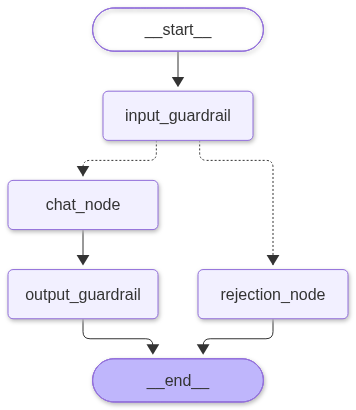

In [17]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())